In [1]:
import pandas as pd
import numpy as np

flower_df = pd.read_csv("../data/processed/iris_cleaned.csv")

# Logistic Regression Model

In [2]:
#Define the features and target variable
x = flower_df.drop("species", axis=1)
y = flower_df["species"]

In [3]:
#Check the shape of the features and target variable

print("Features shape:", x.shape)
print("Target variable shape:", y.shape)


Features shape: (149, 4)
Target variable shape: (149,)


In [4]:
#Split the dataset into training and testing sets

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, 
    y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

#stratify=y ensures the species proportions remain approximately consistent between the two sets.

In [5]:
#Check the shape of the training and testing sets

print("Training features shape:", x_train.shape)
print("Training target variable shape:", y_train.shape)
print("Testing features shape:", x_test.shape)
print("Testing target variable shape:", y_test.shape)

Training features shape: (119, 4)
Training target variable shape: (119,)
Testing features shape: (30, 4)
Testing target variable shape: (30,)


In [6]:
# Feature Scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

StandardScaler is a feature-scaling technique that transforms numerical features to have a mean of approximately 0 and a standard deviation of 1. In our Iris classification project, it is useful for algorithms such as Logistic Regression and K-Nearest Neighbors (KNN), which are sensitive to differences in feature scales. However, it is generally unnecessary for Decision Trees and Random Forests. To prevent data leakage, we fit the scaler on the training data and use the same transformation on the test data.

In [7]:
#Train baseline model and predict on the test set

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaled)

In [8]:
# Evaluate the model's performance using accuracy score 

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9333333333333333


An accuracy score of 93% is decent, but we cannot rely on it fully. We need to evaluate the model using other metrics like F1-score, precision, recall, and confusion matrix.

In [9]:
# Full classification report showcasing precision, recall, and F1-score for each class

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



INTERPRETATION

-> Accuracy = 0.93 means the model correctly classified 28 out of 30 test samples. This is a strong result for a beginner classification project.

-> The model performed perfectly on setosa: all 10 setosa samples were correctly identified. For versicolor and virginica, the model was good but not perfect: it got 9 out of 10 correct for each class.

-> Precision tells us how many predicted positives were actually correct.
For versicolor and virginica, 90% of the predictions for those classes were correct. Recall tells us how many actual positives were captured. Again, 90% for versicolor and virginica, meaning the model missed 1 sample in each class. F1-score combines precision and recall into one number.
0.90 for both versicolor and virginica indicates a balanced but slightly weaker performance than setosa.

-> Macro average = 0.93 means the average performance across the three classes is 93%. Weighted average = 0.93 also reflects this because the test set is balanced (10 samples per class).

Overall conclusion:

The classifier is highly effective and shows strong separation between the species. The main weakness is confusion between versicolor and virginica, while setosa is perfectly classified. The model is reliable for this dataset, with 93% overall accuracy and no errors on setosa.

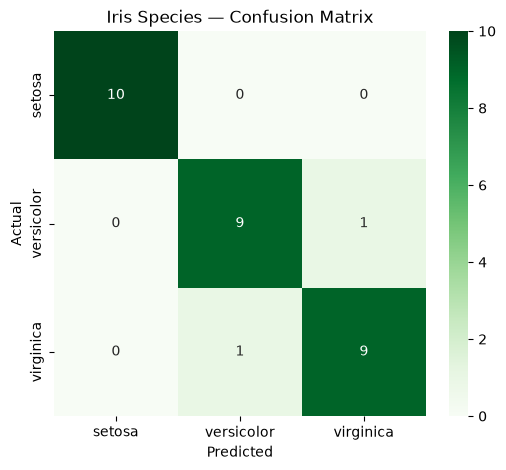

In [10]:
# Confusion Matrix to visualize the performance of the model

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Iris Species — Confusion Matrix")

plt.show()

INTERPRETATION

- The diagonal values represent the correctly classified samples.
- Setosa: 10 out of 10 were correctly classified.
- Versicolor: 9 out of 10 were correctly classified; 1 sample was misclassified as virginica.
- Virginica: 9 out of 10 were correctly classified; 1 sample was misclassified as versicolor.
- Overall, the model achieved an accuracy of 93% (28 out of 30 correctly classified).

This indicates that the classifier performs very well overall. The main confusion is between versicolor and virginica, which is expected because these two species are visually similar. Setosa is perfectly separated from the other classes.

# Decision Tree Classifier

In [11]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(x_train, y_train)

y_pred_tree = decision_tree.predict(x_test)

Unscaled features were used for the tree because scaling is generally unnecessary for this algorithm. The variables x_train_scaled and x_test_scaled were trained for Logistic Regression.

In [12]:
# Evaluate the Decision Tree model's performance 

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print(classification_report(y_test, y_pred_tree))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## Comparison of the 2 models

In [13]:
# Compare both models in a table format to see which one performs better on the test set

predictions = {                           
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_tree
}

results = []

for model_name, predictions_model in predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions_model),
        "Precision": precision_score(
            y_test, predictions_model, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions_model, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions_model, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results).set_index("Model")

comparison_df.round(3)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


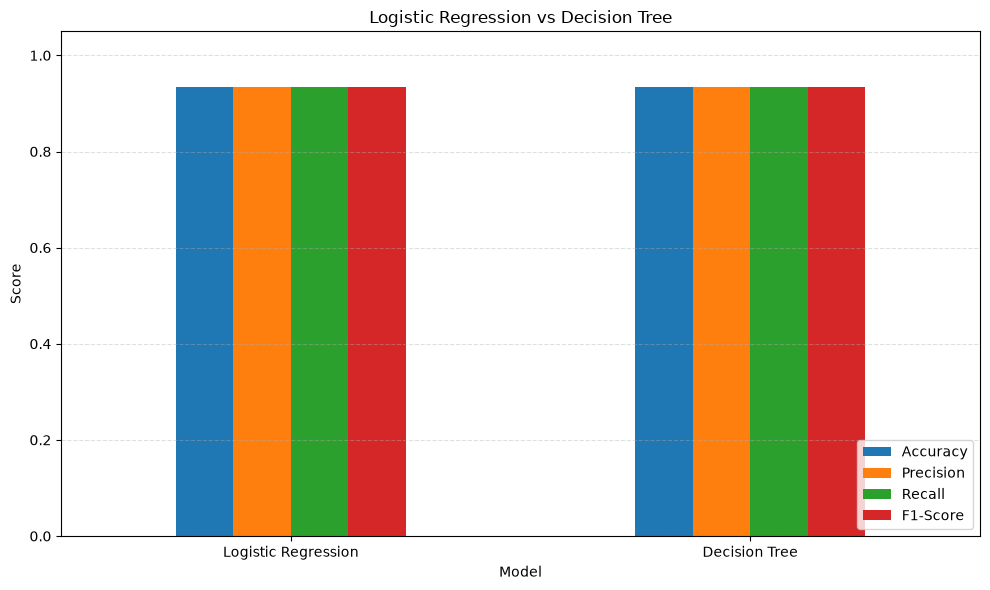

In [14]:
#Visualize the comparison of the two models using a bar chart

comparison_df.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05),
    rot=0
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

INTERPRETATION

The comparison table and bar chart show that **Logistic Regression and the Decision Tree perform equally on this test set**. Both achieve an accuracy, macro-precision, macro-recall, and macro F1-score of **0.933**. The matching bar heights confirm that neither model has a measurable advantage across the reported metrics; each correctly classifies 28 of the 30 test samples.

Based on these results alone, there is no performance-based reason to prefer one model. Logistic Regression offers a simple linear decision boundary, while a Decision Tree can represent more complex decision rules. Because these scores come from one train/test split, cross-validation or testing on additional data would help establish whether this tie holds more generally.

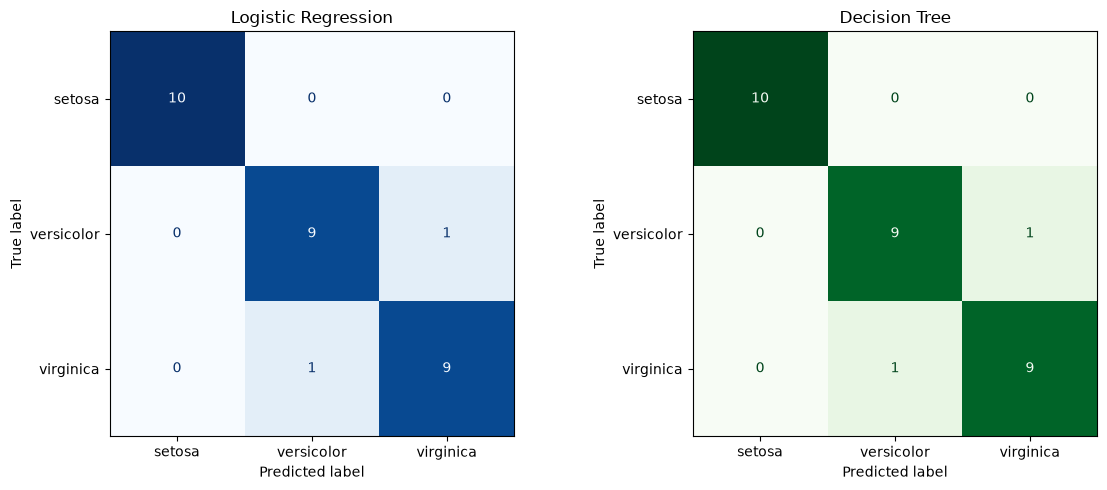

In [21]:
# Compare the confusion matrices of the models

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    ax=axes[0],
    cmap="Blues",
    colorbar=False
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tree,
    ax=axes[1],
    cmap="Greens",
    colorbar=False
)
axes[1].set_title("Decision Tree")

plt.title("Decision Tree")
plt.tight_layout()
plt.show()

INTERPRETATION

The diagonal cells represent correct predictions, while the off-diagonal cells show which classes were mistaken for one another. Both models correctly classify **28 of the 30** test samples, so each matrix contains two misclassifications. This agrees with the comparison table: the models have the same overall performance, while the confusion matrices provide a class-by-class view of their predictions. 

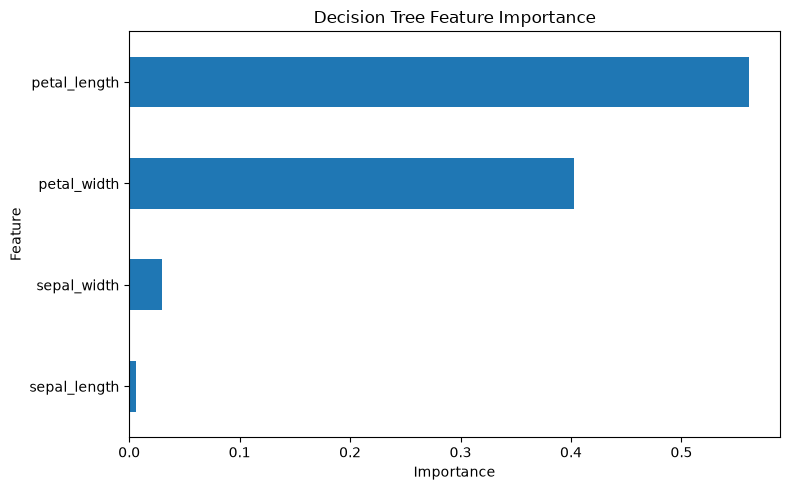

In [16]:
# Plotting decision tree feature importance

feature_importance = pd.Series(
    decision_tree.feature_importances_,
    index=x.columns
).sort_values(ascending=True)

feature_importance.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

INTERPRETATION

The Decision Tree relies mainly on **petal length** (about 0.56 importance) and **petal width** (about 0.40). The two sepal measurements contribute very little in comparison. This suggests the tree makes most of its decisions using petal measurements in this fitted model. Feature importance describes the model's reliance on features; it does not show whether a feature increases or decreases a species prediction, nor does it establish causation.

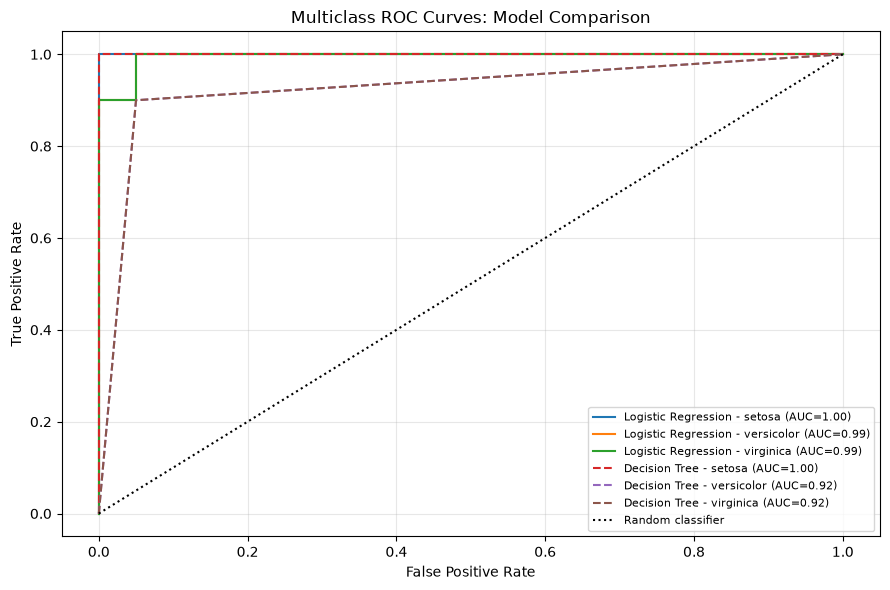

In [17]:
# Plot multi-class ROC curves for both models

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

class_names = list(model.classes_)
y_test_binary = label_binarize(y_test, classes=class_names)

# Predicted probabilities from both models
probabilities = {
    "Logistic Regression": model.predict_proba(x_test_scaled),
    "Decision Tree": decision_tree.predict_proba(x_test)
}

plt.figure(figsize=(9, 6))

for model_name, model_probabilities in probabilities.items():
    for i, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            model_probabilities[:, i]
        )

        roc_auc = auc(fpr, tpr)

        line_style = "-" if model_name == "Logistic Regression" else "--"

        plt.plot(
            fpr,
            tpr,
            linestyle=line_style,
            label=f"{model_name} - {class_name} (AUC={roc_auc:.2f})"
        )

plt.plot([0, 1], [0, 1], "k:", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves: Model Comparison")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

INTERPRETATION

Curves closer to the upper-left corner and with larger AUC values indicate stronger class discrimination than the dotted random-classifier line. Both models discriminate **setosa** very well (AUC 1.00). For **versicolor** and **virginica**, Logistic Regression performs better in this plot (AUC 0.99 for each) than the Decision Tree (AUC 0.92 for each). Thus, despite their equal accuracy on this test split, their probability rankings differ, with Logistic Regression showing stronger class separation for those two species. These AUC estimates are based on the same small test set.

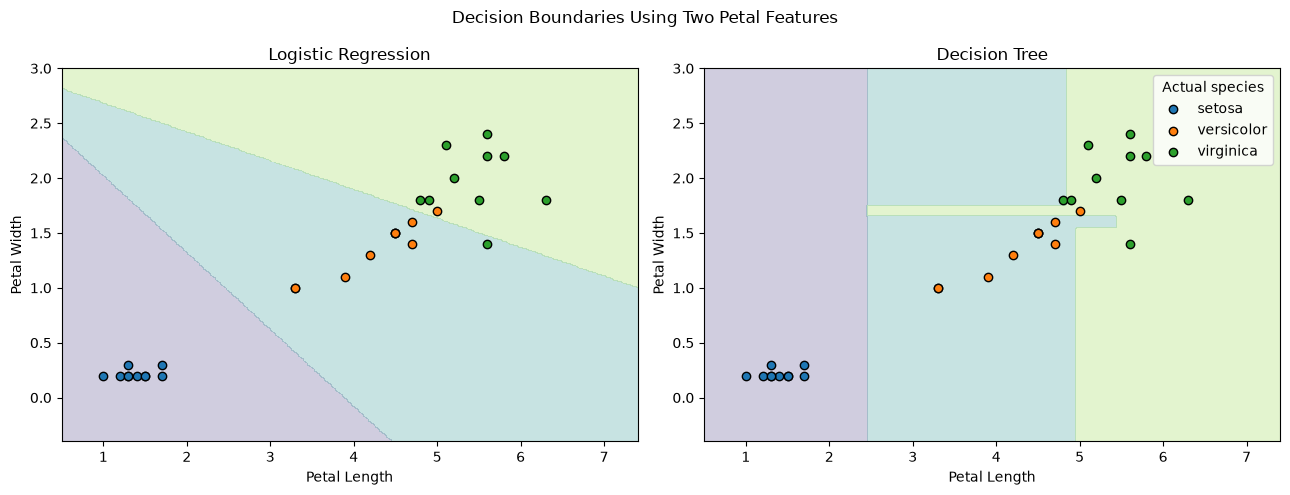

In [18]:
# Visualize the decision boundaries of the Decision Tree model using a 2D scatter plot for two selected features

from sklearn.pipeline import make_pipeline

features_2d = ["petal_length", "petal_width"]

X_train_2d = x_train[features_2d]
X_test_2d = x_test[features_2d]

# Fit two-feature models for visualization only
lr_2d = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
lr_2d.fit(X_train_2d, y_train)

tree_2d = DecisionTreeClassifier(random_state=42)
tree_2d.fit(X_train_2d, y_train)

# Create a grid covering the feature space
x_min = x[features_2d[0]].min() - 0.5
x_max = x[features_2d[0]].max() + 0.5
y_min = x[features_2d[1]].min() - 0.5
y_max = x[features_2d[1]].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = pd.DataFrame({
    features_2d[0]: xx.ravel(),
    features_2d[1]: yy.ravel()
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, fitted_model, title in [
    (axes[0], lr_2d, "Logistic Regression"),
    (axes[1], tree_2d, "Decision Tree")
]:
    predictions_grid = fitted_model.predict(grid)
    class_codes = pd.Categorical(
        predictions_grid,
        categories=class_names
    ).codes.reshape(xx.shape)

    ax.contourf(
        xx, yy, class_codes,
        levels=np.arange(len(class_names) + 1) - 0.5,
        alpha=0.25
    )

    for species in class_names:
        mask = y_test == species
        ax.scatter(
            X_test_2d.loc[mask, features_2d[0]],
            X_test_2d.loc[mask, features_2d[1]],
            label=species,
            edgecolors="black"
        )

    ax.set_title(title)
    ax.set_xlabel("Petal Length")
    ax.set_ylabel("Petal Width")

axes[1].legend(title="Actual species")
plt.suptitle("Decision Boundaries Using Two Petal Features")
plt.tight_layout()
plt.show()

INTERPRETATION

Both plots show that **setosa** is separated clearly using petal length and petal width, while versicolor and virginica occupy closer regions and are harder to distinguish. Logistic Regression forms smoother, slanted boundaries; the Decision Tree creates step-like, axis-aligned regions. The test points show how each two-feature model classifies the observed samples. These boundaries come from models fitted only on the two petal features for visualization, so they illustrate the feature-space pattern rather than the exact boundaries of the full-feature models compared above.

## Overall Conclusion

Both Logistic Regression and the Decision Tree performed well on the Iris test set, correctly classifying **28 of 30 samples (93.3% accuracy)**. Their macro-precision, macro-recall, and macro F1-score are also 0.933, so the standard classification metrics show a tie. The class-level results indicate that setosa was classified perfectly by Logistic Regression, while most of the remaining errors involve distinguishing versicolor from virginica.

The additional visualizations show complementary strengths: the Decision Tree bases most of its decisions on petal length and petal width, while the ROC curves give Logistic Regression higher AUC for versicolor and virginica on this split. The two-feature decision-boundary plots also show why those species are more difficult to separate, though these plots use only petal length and width and are for visualization.

Overall, either model is a reasonable choice for this dataset based on the observed accuracy. Logistic Regression has a slight edge in the ROC comparison, but the evaluation uses only one small train/test split; cross-validation and testing on additional data are recommended before concluding that one model generalizes better.